# CSCI218 Project: Humanitarian Warehouse Demand Forecasting
## Part 4: Evaluation (P4)

This notebook compares every forecasting model on the **same test weeks** using **MAE** and **RMSE**, repeats the random models over several seeds, and breaks the errors down by supply category.

- **Input:** `clean_weekly_demand.csv` (from P1) and `nn_predictions.csv` (from P3), in the same folder as this notebook
- **Models compared:** Naive, 4-week moving average (baselines), Decision Tree and Random Forest (P2), Neural network (P3)
- **Repeated runs:** every model with randomness is trained with 5 seeds and reported as mean ± std
- **Test period:** the last 20% of weeks (29 Mar 2026 to 25 Oct 2026), 434 item-weeks

## 1. Load the data and rebuild the same features as P2
The features must be **exactly** the same as in P2's notebook, otherwise the comparison is not fair.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

df = pd.read_csv('clean_weekly_demand.csv', parse_dates=['week_end'])

y = df['demand_units']
X = df.drop(['demand_units', 'week_end', 'item_name', 'category', 'sku',
             'split', 'stockout_this_week'], axis=1)
X['lag_52_missing'] = X['lag_52'].isna().astype(int)
X['lag_52'] = X['lag_52'].fillna(0)

train = df['split'] == 'train'
test = df['split'] == 'test'
X_train, X_test = X[train], X[test]
y_train, y_test = y[train], y[test]

print('Train:', X_train.shape, '| Test:', X_test.shape)
print('Test weeks:', df.loc[test, 'week_end'].min().date(), 'to', df.loc[test, 'week_end'].max().date())

Train: (1680, 44) | Test: (434, 44)
Test weeks: 2026-03-29 to 2026-10-25


## 2. Metrics
- **MAE** (mean absolute error): on average, how many units the forecast is off by.
- **RMSE** (root mean squared error): like MAE, but big misses count much more. A big gap between RMSE and MAE means the model sometimes makes large mistakes, which is what causes shortages.

Lower is better for both.

In [3]:
def evaluate(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    return mae, rmse

# one table that collects every model's test predictions, row by row
preds = df.loc[test, ['week_end', 'sku', 'item_name', 'category', 'demand_units']].copy()

## 3. Baselines
A model is only useful if it beats these simple rules.

In [4]:
preds['Naive'] = X_test['lag_1']                 # next week = last week
preds['Moving average'] = X_test['rolling_mean_4']  # next week = average of last 4 weeks

for m in ['Naive', 'Moving average']:
    mae, rmse = evaluate(y_test, preds[m])
    print(f'{m:15s} MAE {mae:6.2f}  RMSE {rmse:6.2f}')

Naive           MAE  25.20  RMSE  39.47
Moving average  MAE  25.94  RMSE  49.31


**LINEAR** **REGRESSION**

In [5]:
from sklearn.linear_model import LinearRegression

# Linear regression: fits one straight-line formula using all the clues (no randomness, so one run is enough)
lr = LinearRegression().fit(X_train, y_train)
preds['Linear regression'] = lr.predict(X_test)

mae, rmse = evaluate(y_test, preds['Linear regression'])
print(f"Linear regression  MAE {mae:.2f}  RMSE {rmse:.2f}")

Linear regression  MAE 24.11  RMSE 35.07


## 4. Repeated runs: Decision Tree and Random Forest
These models involve randomness, so one run could be lucky. Each one is trained with **5 different random seeds** (same settings as P2), and we report the **mean ± standard deviation**.

In [6]:
SEEDS = [0, 1, 2, 3, 4]
runs = []

for seed in SEEDS:
    dt = DecisionTreeRegressor(max_depth=8, min_samples_leaf=5, random_state=seed)
    dt.fit(X_train, y_train)
    mae, rmse = evaluate(y_test, dt.predict(X_test))
    runs.append({'Model': 'Decision Tree', 'seed': seed, 'MAE': mae, 'RMSE': rmse})

    rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=seed, n_jobs=-1)
    rf.fit(X_train, y_train)
    rf_pred = rf.predict(X_test)
    mae, rmse = evaluate(y_test, rf_pred)
    runs.append({'Model': 'Random Forest', 'seed': seed, 'MAE': mae, 'RMSE': rmse})

# keep the seed-0 predictions for the charts below
preds['Decision Tree'] = DecisionTreeRegressor(max_depth=8, min_samples_leaf=5, random_state=0).fit(X_train, y_train).predict(X_test)
preds['Random Forest'] = RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=0, n_jobs=-1).fit(X_train, y_train).predict(X_test)

runs = pd.DataFrame(runs)
runs.groupby('Model')[['MAE', 'RMSE']].agg(['mean', 'std']).round(2)

MAE         RMSE      
                mean   std   mean   std
Model                                  
Decision Tree  22.93  0.12  34.80  0.17
Random Forest  19.79  0.08  30.92  0.25

## 5. Neural network (P3)
P3 trained a Keras network (64 → 32 → 1, ReLU, Adam, MSE loss, 50 epochs, batch size 32) on scaled features and saved its test predictions as `nn_predictions.csv` (columns `Actual, Predicted`, in the same row order as the test set).

**5a.** First we check that P3's saved file lines up with our test rows and score it.

In [8]:
if os.path.exists('nn_predictions.csv'):
    nn_file = pd.read_csv('nn_predictions.csv')
    assert len(nn_file) == len(preds), 'NN file must have one row per test item-week (434)'
    assert (nn_file['Actual'].values == preds['demand_units'].values).all(), 'NN rows are not in the same order as the test set'
    preds['Neural network'] = nn_file['Predicted'].values
    mae, rmse = evaluate(nn_file['Actual'], nn_file['Predicted'])
    print(f"P3's saved run:  MAE {mae:.2f}  RMSE {rmse:.2f}")
else:
    print('nn_predictions.csv not found: put P3\'s file in the same folder as this notebook.')

P3's saved run:  MAE 25.60  RMSE 36.43


**5b. Repeated runs.** A neural network starts from random weights, so one run is not enough. We retrain **the exact same network** with the same 5 seeds as the tree models.

In [9]:
import tensorflow as tf
from tensorflow.keras import Sequential, Input
from tensorflow.keras.layers import Dense
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

def build_nn():
    nn = Sequential([Input(shape=(X_train_s.shape[1],)),
                     Dense(64, activation='relu'),
                     Dense(32, activation='relu'),
                     Dense(1)])
    nn.compile(optimizer='adam', loss='mse')
    return nn

for seed in SEEDS:
    tf.keras.utils.set_random_seed(seed)
    nn = build_nn()
    nn.fit(X_train_s, y_train, epochs=50, batch_size=32, validation_split=0.1, verbose=0)
    p = nn.predict(X_test_s, verbose=0).flatten()
    mae, rmse = evaluate(y_test, p)
    runs = pd.concat([runs, pd.DataFrame([{'Model': 'Neural network', 'seed': seed, 'MAE': mae, 'RMSE': rmse}])], ignore_index=True)
    print(f'seed {seed}: MAE {mae:.2f}  RMSE {rmse:.2f}')
    if 'Neural network' not in preds:
        preds['Neural network'] = p

seed 0: MAE 25.57  RMSE 36.34
seed 1: MAE 25.17  RMSE 36.76
seed 2: MAE 26.23  RMSE 37.72
seed 3: MAE 27.14  RMSE 38.68
seed 4: MAE 27.94  RMSE 40.57


**5c. Extra experiment: is the network under-trained?** In P3's training log the validation loss was still falling at epoch 50, so i tried **150 epochs** (everything else the same). This is reported in addition  and does not replace P3's model.

In [10]:
for seed in SEEDS:
    tf.keras.utils.set_random_seed(seed)
    nn = build_nn()
    nn.fit(X_train_s, y_train, epochs=150, batch_size=32, validation_split=0.1, verbose=0)
    p = nn.predict(X_test_s, verbose=0).flatten()
    mae, rmse = evaluate(y_test, p)
    runs = pd.concat([runs, pd.DataFrame([{'Model': 'Neural network (150 epochs)', 'seed': seed, 'MAE': mae, 'RMSE': rmse}])], ignore_index=True)
    print(f'seed {seed}: MAE {mae:.2f}  RMSE {rmse:.2f}')

seed 0: MAE 20.68  RMSE 30.00
seed 1: MAE 22.51  RMSE 31.95
seed 2: MAE 20.98  RMSE 29.63
seed 3: MAE 22.32  RMSE 31.87
seed 4: MAE 22.47  RMSE 32.26


## 6. Final comparison table

In [11]:
rows = []
for m in ['Naive', 'Moving average', 'Linear regression']:
    mae, rmse = evaluate(y_test, preds[m])
    rows.append({'Model': m, 'MAE': mae, 'MAE std': 0.0, 'RMSE': rmse, 'RMSE std': 0.0})
for m, g in runs.groupby('Model'):
    rows.append({'Model': m, 'MAE': g['MAE'].mean(), 'MAE std': g['MAE'].std(),
                 'RMSE': g['RMSE'].mean(), 'RMSE std': g['RMSE'].std()})
results = pd.DataFrame(rows)

naive_mae = results.loc[results['Model'] == 'Naive', 'MAE'].item()
naive_rmse = results.loc[results['Model'] == 'Naive', 'RMSE'].item()
results['MAE vs naive'] = ((naive_mae - results['MAE']) / naive_mae * 100).round(1).astype(str) + '%'
results['RMSE vs naive'] = ((naive_rmse - results['RMSE']) / naive_rmse * 100).round(1).astype(str) + '%'
results = results.sort_values('MAE').round(2)
results

,Model,MAE,MAE std,RMSE,RMSE std,MAE vs naive,RMSE vs naive
6,Random Forest,19.79,0.08,30.92,0.25,21.5%,21.6%
5,Neural network (150 epochs),21.79,0.89,31.14,1.23,13.5%,21.1%
3,Decision Tree,22.93,0.12,34.80,0.17,9.0%,11.8%
2,Linear regression,24.11,0.00,35.07,0.00,4.3%,11.1%
0,Naive,25.20,0.00,39.47,0.00,0.0%,0.0%
1,Moving average,25.94,0.00,49.31,0.00,-2.9%,-24.9%
4,Neural network,26.41,1.13,38.01,1.69,-4.8%,3.7%


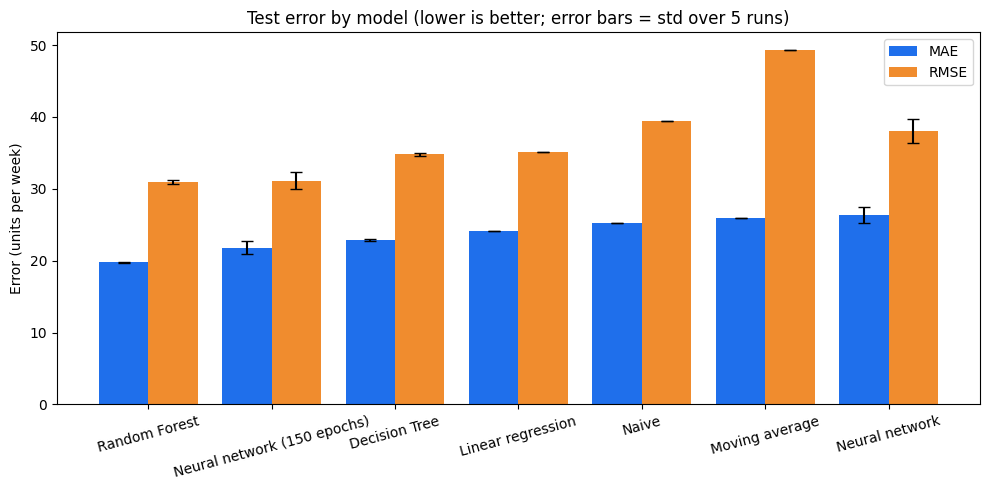

In [12]:
models = list(results['Model'])
x = np.arange(len(models))
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(x - 0.2, results['MAE'], 0.4, yerr=results['MAE std'], capsize=4, label='MAE', color='#1f6feb')
ax.bar(x + 0.2, results['RMSE'], 0.4, yerr=results['RMSE std'], capsize=4, label='RMSE', color='#f08c2e')
ax.set_xticks(x)
ax.set_xticklabels(models, rotation=15)
ax.set_ylabel('Error (units per week)')
ax.set_title('Test error by model (lower is better; error bars = std over 5 runs)')
ax.legend()
plt.tight_layout()
plt.savefig('fig_model_comparison.png', dpi=150)
plt.show()

## 7. Error by supply category
Food & Nutrition has much higher demand than the other categories, so its errors in units will naturally be larger.

In [13]:
model_cols = [m for m in ['Naive', 'Moving average', 'Linear regression', 'Decision Tree', 'Random Forest', 'Neural network'] if m in preds]
cat_mae = pd.DataFrame({m: (preds['demand_units'] - preds[m]).abs().groupby(preds['category']).mean() for m in model_cols})
cat_mae.insert(0, 'Avg demand', preds.groupby('category')['demand_units'].mean())
cat_mae.round(1)

,Avg demand,Naive,Moving average,Linear regression,Decision Tree,Random Forest,Neural network
category,,,,,,,
Food & Nutrition,268.8,45.0,52.8,39.6,41.0,36.9,36.2
Medical,106.3,15.6,11.9,17.6,14.2,12.1,15.2
Shelter & NFI,124.0,19.4,18.5,18.9,17.0,14.6,17.6
WASH,105.0,14.5,11.8,16.0,13.9,10.8,40.2


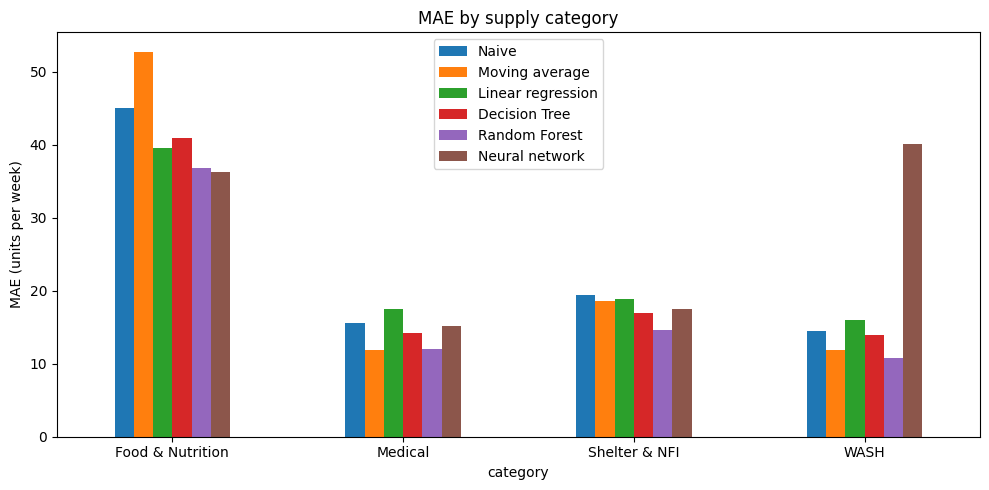

In [14]:
cat_mae.drop(columns='Avg demand').plot(kind='bar', figsize=(10, 5), rot=0)
plt.ylabel('MAE (units per week)')
plt.title('MAE by supply category')
plt.tight_layout()
plt.savefig('fig_mae_by_category.png', dpi=150)
plt.show()

## 8. Actual vs predicted over the test weeks
One item from the hardest category (Food & Nutrition), so we can see where each model goes wrong.

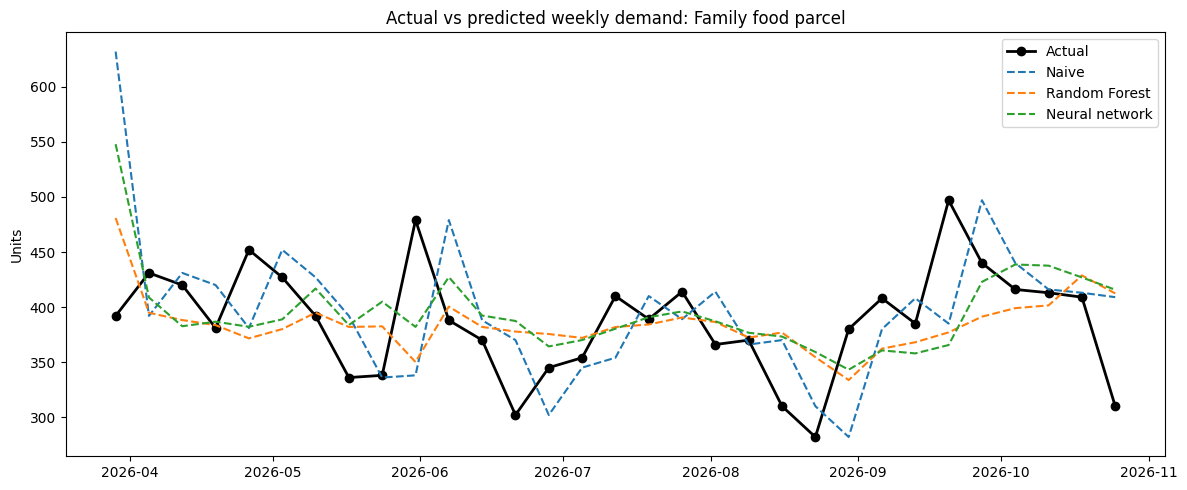

In [15]:
item = 'Family food parcel'
d = preds[preds['item_name'] == item].sort_values('week_end')
plt.figure(figsize=(12, 5))
plt.plot(d['week_end'], d['demand_units'], 'k-o', label='Actual', linewidth=2)
for m in ['Naive', 'Random Forest', 'Neural network']:
    if m in d:
        plt.plot(d['week_end'], d[m], '--', label=m)
plt.title(f'Actual vs predicted weekly demand: {item}')
plt.ylabel('Units')
plt.legend()
plt.tight_layout()
plt.savefig('fig_actual_vs_predicted.png', dpi=150)
plt.show()

## 9. Where does the best model go wrong?


In [16]:
best = results.iloc[0]['Model'] if results.iloc[0]['Model'] in preds else 'Random Forest'
preds['error'] = preds[best] - preds['demand_units']   # negative = forecast too low
print(f'Best model: {best}')
print(f'Forecast too low in {(preds["error"] < 0).mean():.0%} of item-weeks')
print('\nFive largest misses:')
preds.loc[preds['error'].abs().nlargest(5).index, ['week_end', 'item_name', 'demand_units', best, 'error']].round(0)

Best model: Random Forest
Forecast too low in 53% of item-weeks

Five largest misses:


,week_end,item_name,demand_units,Random Forest,error
422,2026-03-29,Rice 25 kg,200,393.0,193.0
280,2026-05-31,High-energy biscuits,417,269.0,-148.0
296,2026-09-20,High-energy biscuits,449,304.0,-145.0
129,2026-05-31,Family food parcel,479,350.0,-129.0
432,2026-06-07,Rice 25 kg,197,322.0,125.0


In [17]:
results.to_csv('model_comparison_results.csv', index=False)
preds.to_csv('all_test_predictions.csv', index=False)
print('Saved model_comparison_results.csv and all_test_predictions.csv for P5 and the report')

Saved model_comparison_results.csv and all_test_predictions.csv for P5 and the report


## Part 5: Integration + Shortage Detection (P5)

This part combines demand forecasts with the warehouse stock levels and raises a **shortage alert** for every item (SKU), so the warehouse knows what to reorder before it runs out.

- **Input:** `clean_weekly_demand.csv` (P1's cleaned weekly table) and the `preds` table built in sections 3 to 9 above (the same table saved as `all_test_predictions.csv`: P2's Decision Tree and Random Forest, P3's Neural network)
- **Forecasts:** the team's predictions on the test split, plus models P5 retrains from the CSV (Naive, Moving average, Linear regression, Random Forest, Gradient boosting) so the alerts can also be backtested over a longer period
- **Alert levels:** CRITICAL, HIGH, WARNING, OK, based on how much stock is left after the week's predicted demand
- **Check:** every alert is compared with whether a real stockout happened that week (`stockout_this_week`)

## 10. Setup and load the data

In [18]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor

df = pd.read_csv('clean_weekly_demand.csv', parse_dates=['week_end'])
df = df.sort_values(['sku', 'week_end']).reset_index(drop=True)
os.makedirs('outputs', exist_ok=True)

weeks = sorted(df['week_end'].unique())
print(df.shape)
print('Weeks:', pd.Timestamp(weeks[0]).date(), 'to', pd.Timestamp(weeks[-1]).date(), f'({len(weeks)} weeks),',
      df['sku'].nunique(), 'items')
print(df.groupby('split')['week_end'].agg(['min', 'max', 'nunique']))
print('Real stockout weeks:', int(df['stockout_this_week'].sum()),
      '| in the test split:', int(df.loc[df['split'] == 'test', 'stockout_this_week'].sum()))
df[['week_end', 'sku', 'item_name', 'demand_units', 'stock_start_units', 'on_order_start_units',
    'stockout_this_week', 'split']].head()

(2114, 50)
Weeks: 2023-12-10 to 2026-10-25 (151 weeks), 14 items
             min        max  nunique
split                               
test  2026-03-29 2026-10-25       31
train 2023-12-10 2026-03-22      120
Real stockout weeks: 28 | in the test split: 0


,week_end,sku,item_name,demand_units,stock_start_units,on_order_start_units,stockout_this_week,split
0,2023-12-10,SKU-101,Family food parcel,387,500.0,0.0,0,train
1,2023-12-17,SKU-101,Family food parcel,332,113.0,894.0,0,train
2,2023-12-24,SKU-101,Family food parcel,423,675.0,0.0,0,train
3,2023-12-31,SKU-101,Family food parcel,332,252.0,902.0,0,train
4,2024-01-07,SKU-101,Family food parcel,343,822.0,0.0,0,train


## 11. What the stock columns mean
For each item and week the CSV gives:

- `stock_start_units`: stock on hand at the **start** of the week
- `on_order_start_units`: stock on order at the start of the week, which **arrives during that week**
- `demand_units`: units dispatched during the week
- `stockout_this_week`: 1 if the stock ran out during the week

So the stock available for the week is `stock_start + on_order_start`, and a stockout happens when demand is bigger than that. The check below confirms this rule matches the stockout flag.

In [19]:
short = (df['stock_start_units'] + df['on_order_start_units'] < df['demand_units']).astype(int)
pd.crosstab(short, df['stockout_this_week'], rownames=['available < demand'], colnames=['stockout_this_week'])

stockout_this_week,0,1
available < demand,,
0,2086,3
1,0,25


## 12. The shortage alert rule
At the start of week *t* we know the stock on hand and the stock arriving this week, but not the demand, so we use the **predicted** demand:

**projected stock at the end of the week = stock at start + on order − predicted demand**

We divide this by the predicted demand (the **cover ratio**), so the rule works the same for big items (food parcels) and small items (trauma kits):

| Alert | Cover ratio | Meaning |
|---|---|---|
| **CRITICAL** | below 0 | predicted to run out this week |
| **HIGH** | below 0.25 | less than a quarter of a week of demand left |
| **WARNING** | below 0.5 | less than half a week of demand left |
| **OK** | 0.5 or more | enough stock |

In [20]:
CRIT_RATIO, HIGH_RATIO, WARN_RATIO = 0.0, 0.25, 0.5
ALERT_ORDER = {'CRITICAL': 0, 'HIGH': 1, 'WARNING': 2, 'OK': 3}
COLORS = {'CRITICAL': '#c0392b', 'HIGH': '#e67e22', 'WARNING': '#f1c40f', 'OK': '#7fb77e'}

def alert_level(ratio):
    if ratio < CRIT_RATIO:
        return 'CRITICAL'
    if ratio < HIGH_RATIO:
        return 'HIGH'
    if ratio < WARN_RATIO:
        return 'WARNING'
    return 'OK'

def assess(stock_start, on_order, pred):
    # works on single numbers or on whole columns
    pred = np.maximum(np.asarray(pred, dtype=float), 1e-9)
    available = np.asarray(stock_start, dtype=float) + np.asarray(on_order, dtype=float)
    projected = available - pred
    ratio = projected / pred
    return pd.DataFrame({'projected_stock_end': np.round(projected, 1),
                         'cover_ratio': np.round(ratio, 2),
                         'weeks_of_cover': np.round(available / pred, 2),
                         'shortfall_units': np.round(np.maximum(0, -projected), 1),
                         'alert': [alert_level(r) for r in np.atleast_1d(ratio)]})

# quick example: 100 on hand, 20 arriving, 150 predicted -> 30 short
assess([100], [20], [150])

,projected_stock_end,cover_ratio,weeks_of_cover,shortfall_units,alert
0,-30.0,-0.2,0.8,30.0,CRITICAL


## 13. Forecasts from the CSV
All models use the features P1 already built in the CSV. Every feature is known before the week starts (lagged demand, calendar, emergency flags, item and category dummies), so there is no leakage. The stock columns are **not** used as features: the forecast is about demand only, and the stock comes in at the alert step.

- **Naive:** last week's demand (`lag_1`)
- **Moving average:** mean of the last 4 weeks (`rolling_mean_4`)
- **Linear regression, Random Forest, Gradient boosting:** retrained by P5 on the `train` split
- **Decision Tree (P2), Random Forest (P2), Neural network (P3):** read from the `preds` table (section 9). It is checked against the CSV (same weeks, same items, same demand). These exist only for the test weeks, so they are used in sections 14 to 16a but not in the longer walk-forward backtest

`lag_52` is empty for the first year; gradient boosting handles missing values itself, and for the other models it is filled with `rolling_mean_4`.

In [21]:
SEED = 42
FEATURES = (['lag_1', 'lag_2', 'lag_4', 'rolling_mean_4', 'lag_52',
             'is_ramadan', 'is_eid_al_adha_week', 'is_winterization', 'week_of_year', 'month',
             'active_emergencies', 'max_severity']
            + [c for c in df.columns if c.startswith(('emerg_', 'cat_', 'season_', 'sku_'))])

def get_X(data, fill=True):
    x = data[FEATURES].copy()
    if fill:
        x['lag_52'] = x['lag_52'].fillna(x['rolling_mean_4'])
    return x

def fit_predict(train, test):
    # returns a DataFrame of predictions (one column per model) for the rows in `test`
    y = train['demand_units']
    lr = LinearRegression().fit(get_X(train), y)
    rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=SEED, n_jobs=-1).fit(get_X(train), y)
    gb = HistGradientBoostingRegressor(learning_rate=0.05, max_iter=400, max_leaf_nodes=31,
                                       min_samples_leaf=20, random_state=SEED).fit(get_X(train, fill=False), y)
    preds = pd.DataFrame({'Naive': test['lag_1'],
                          'Moving average': test['rolling_mean_4'],
                          'Linear regression': lr.predict(get_X(test)),
                          'Random Forest': rf.predict(get_X(test)),
                          'Gradient boosting': gb.predict(get_X(test, fill=False))}, index=test.index)
    return preds.clip(lower=0)          # demand can't be negative

MODELS = ['Naive', 'Moving average', 'Linear regression', 'Random Forest', 'Gradient boosting']
train_df, test_df = df[df['split'] == 'train'], df[df['split'] == 'test']
test_preds = fit_predict(train_df, test_df)

def metrics(y, p):
    e = np.asarray(y) - np.asarray(p)
    return dict(MAE=round(float(np.abs(e).mean()), 2), RMSE=round(float(np.sqrt((e ** 2).mean())), 2))

# ---- the team's own test predictions (P2 + P3) ----
team = preds.copy()                 # P2 + P3 test predictions from section 9
TEAM_COLS = {'Decision Tree': 'Decision Tree (P2)', 'Random Forest': 'Random Forest (P2)',
             'Neural network': 'Neural network (P3)'}
merged = test_df[['week_end', 'sku', 'demand_units']].reset_index().merge(
    team, on=['week_end', 'sku'], how='left', suffixes=('', '_team')).set_index('index')
assert merged[list(TEAM_COLS)].notna().all().all(), 'team file does not cover every test row'
assert (merged['demand_units'] == merged['demand_units_team']).all(), 'team file demand does not match the CSV'
for src, name in TEAM_COLS.items():
    test_preds[name] = merged.loc[test_preds.index, src].clip(lower=0)

TEST_MODELS = MODELS + list(TEAM_COLS.values())
forecast_metrics = pd.DataFrame([dict(Model=m, **metrics(test_df['demand_units'], test_preds[m]))
                                 for m in TEST_MODELS]).sort_values('MAE').reset_index(drop=True)
forecast_metrics.to_csv('outputs/forecast_metrics_test.csv', index=False)
forecast_metrics

,Model,MAE,RMSE
0,Random Forest (P2),19.88,31.16
1,Random Forest,19.91,30.63
2,Gradient boosting,21.26,32.33
3,Decision Tree (P2),22.82,34.67
4,Linear regression,23.68,34.17
5,Naive,25.20,39.47
6,Neural network (P3),25.60,36.43
7,Moving average,25.94,49.31


## 14. Connect the forecasts to the stock
`run_alerts` takes the stock rows and one column of predicted demand and returns the alert table. `predictions_long` keeps every model's prediction next to the stock and the real outcome, which is also saved for the report.

In [22]:
def run_alerts(rows, pred):
    a = assess(rows['stock_start_units'].values, rows['on_order_start_units'].values, pred.values)
    out = pd.concat([rows[['week_end', 'sku', 'item_name', 'stock_start_units', 'on_order_start_units',
                           'demand_units', 'stockout_this_week']].reset_index(drop=True),
                     pd.Series(np.round(pred.values, 1), name='pred_demand'), a], axis=1)
    return out

predictions_long = pd.concat([run_alerts(test_df, test_preds[m]).assign(model=m) for m in TEST_MODELS],
                             ignore_index=True)
predictions_long.to_csv('outputs/test_alerts_all_models.csv', index=False)
predictions_long.head()

,week_end,sku,item_name,stock_start_units,on_order_start_units,demand_units,stockout_this_week,pred_demand,projected_stock_end,cover_ratio,weeks_of_cover,shortfall_units,alert,model
0,2026-03-29,SKU-101,Family food parcel,336.0,717.0,392,0,632.0,421.0,0.67,1.67,0.0,OK,Naive
1,2026-04-05,SKU-101,Family food parcel,661.0,0.0,431,0,392.0,269.0,0.69,1.69,0.0,OK,Naive
2,2026-04-12,SKU-101,Family food parcel,230.0,641.0,420,0,431.0,440.0,1.02,2.02,0.0,OK,Naive
3,2026-04-19,SKU-101,Family food parcel,451.0,533.0,381,0,420.0,564.0,1.34,2.34,0.0,OK,Naive
4,2026-04-26,SKU-101,Family food parcel,603.0,0.0,452,0,381.0,222.0,0.58,1.58,0.0,OK,Naive


## 15. Latest shortage alerts (best model)
The model with the lowest test MAE (team or P5) is used for the live alert table, for the last week in the data.

In [23]:
BEST = forecast_metrics.loc[0, 'Model']
latest = test_df['week_end'].max()
rows = test_df[test_df['week_end'] == latest]
alerts = (run_alerts(rows, test_preds.loc[rows.index, BEST])
          .sort_values(['alert', 'cover_ratio'], key=lambda s: s.map(ALERT_ORDER) if s.name == 'alert' else s)
          .reset_index(drop=True))
alerts.to_csv('outputs/shortage_alerts_latest.csv', index=False)
print(f'Shortage alerts for the week ending {latest.date()} ({BEST} forecast):')
alerts[['sku', 'item_name', 'stock_start_units', 'on_order_start_units', 'pred_demand',
        'projected_stock_end', 'weeks_of_cover', 'alert']]

Shortage alerts for the week ending 2026-10-25 (Random Forest (P2) forecast):


,sku,item_name,stock_start_units,on_order_start_units,pred_demand,projected_stock_end,weeks_of_cover,alert
0,SKU-402,Jerrycan bundle,171.0,0.0,137.3,33.7,1.25,HIGH
1,SKU-101,Family food parcel,566.0,0.0,412.4,153.6,1.37,WARNING
2,SKU-102,High-energy biscuits,419.0,0.0,304.3,114.7,1.38,WARNING
3,SKU-303,"Medicines (essential, box)",155.0,0.0,111.2,43.8,1.39,WARNING
4,SKU-205,Kitchen set,128.0,0.0,79.1,48.9,1.62,OK
5,SKU-203,Thermal blankets (bale of 10),220.0,254.0,291.0,183.0,1.63,OK
6,SKU-201,Family tent,42.0,90.0,76.7,55.3,1.72,OK
7,SKU-301,First aid kit,299.0,0.0,168.4,130.6,1.78,OK
8,SKU-202,Tarpaulin,131.0,330.0,258.2,202.8,1.79,OK
9,SKU-103,Rice 25 kg,318.0,322.0,303.5,336.5,2.11,OK


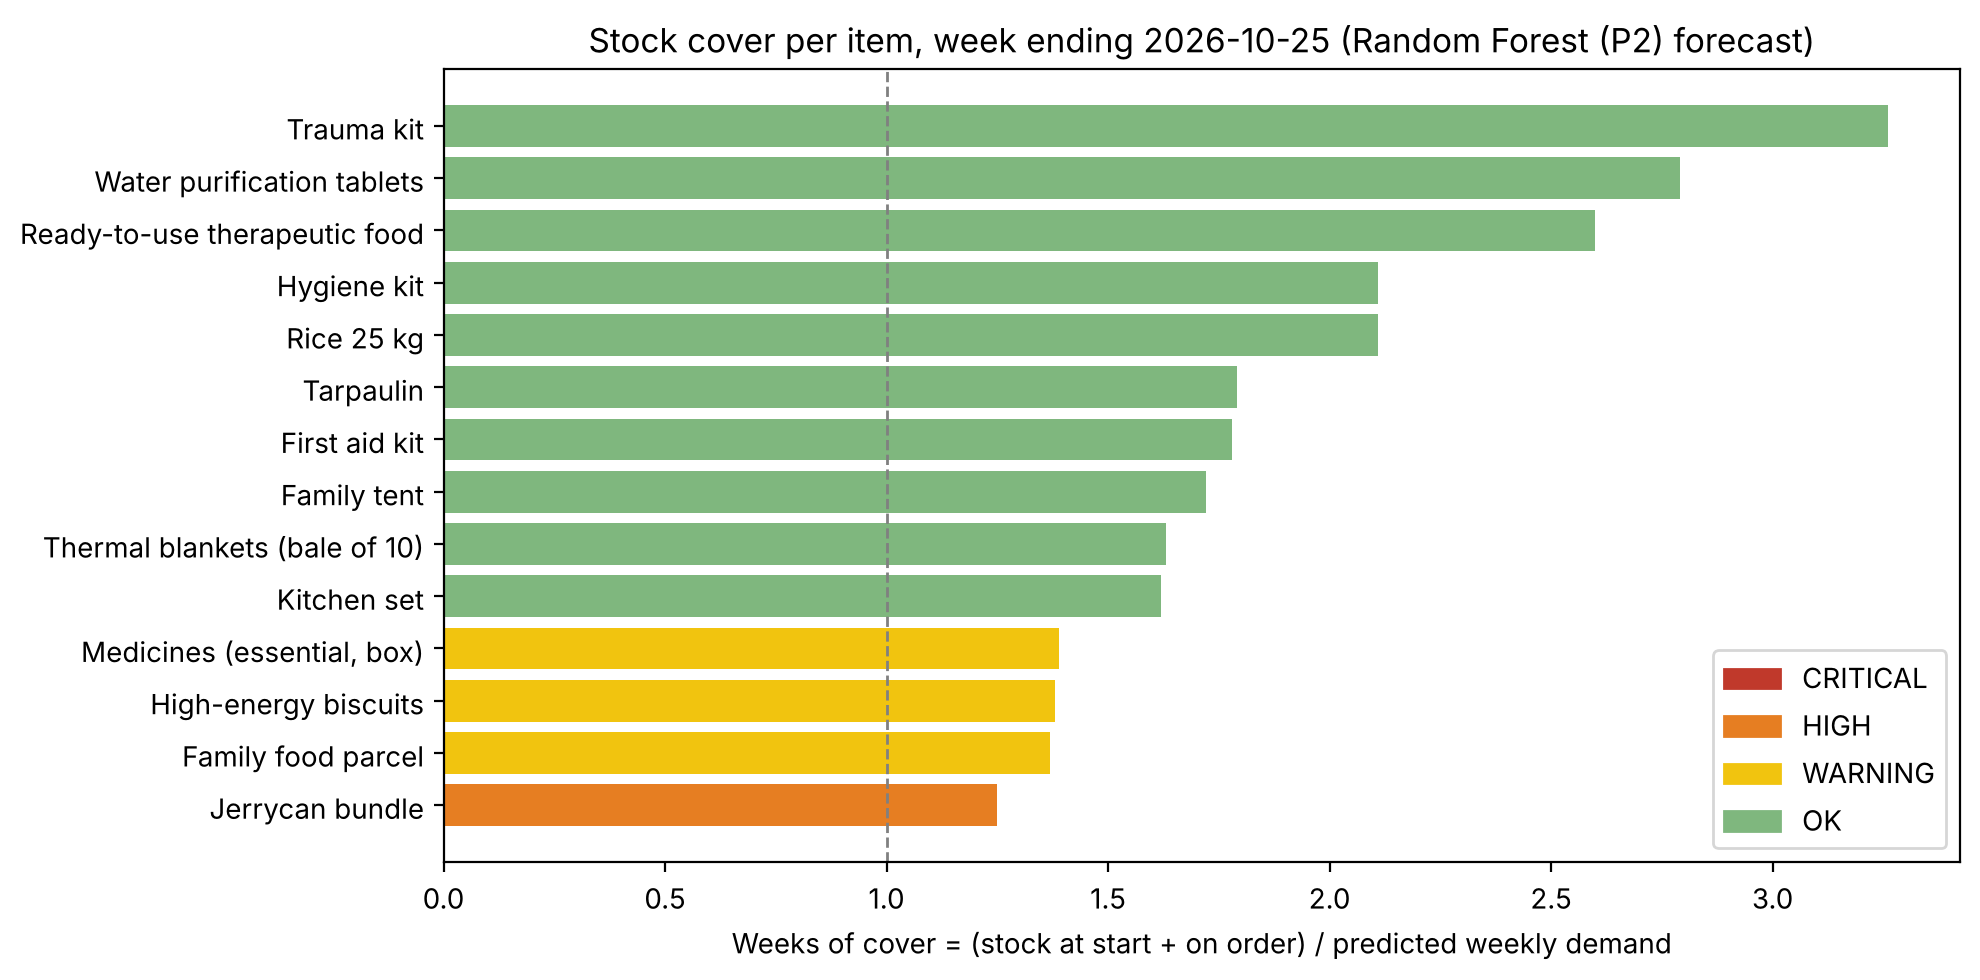

In [24]:
a = alerts.sort_values('weeks_of_cover')
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(a['item_name'], a['weeks_of_cover'], color=[COLORS[x] for x in a['alert']])
ax.axvline(1, ls='--', c='grey', lw=1)
ax.set_xlabel('Weeks of cover = (stock at start + on order) / predicted weekly demand')
ax.set_title(f'Stock cover per item, week ending {latest.date()} ({BEST} forecast)')
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in COLORS.values()]
ax.legend(handles, COLORS.keys(), loc='lower right')
plt.tight_layout()
plt.savefig('fig_cover_by_sku.png', dpi=150)
plt.show()

## 16. Backtest: do the alerts match real stockouts?
For every week and item we raise an alert from the predicted demand, then check whether a **real stockout** happened that week.

- **Precision:** of the alerts we raised, how many were real stockouts
- **Recall:** of the real stockouts, how many we warned about

We test three ways of using the alerts: act on CRITICAL only, on CRITICAL + HIGH, or on CRITICAL + HIGH + WARNING.

In [25]:
def score(bt, flag_levels):
    flagged = bt['alert'].isin(flag_levels).astype(int)
    y = bt['stockout_this_week']
    tp, fp = int(((flagged == 1) & (y == 1)).sum()), int(((flagged == 1) & (y == 0)).sum())
    fn, tn = int(((flagged == 0) & (y == 1)).sum()), int(((flagged == 0) & (y == 0)).sum())
    prec = tp / (tp + fp) if tp + fp else float('nan')
    rec = tp / (tp + fn) if tp + fn else float('nan')
    return dict(flag=', '.join(flag_levels), TP=tp, FP=fp, FN=fn, TN=tn,
                precision=round(prec, 3), recall=round(rec, 3))

def scores_table(bt):
    return pd.DataFrame([score(bt, ['CRITICAL']), score(bt, ['CRITICAL', 'HIGH']),
                         score(bt, ['CRITICAL', 'HIGH', 'WARNING'])])

### 16a. Every model on the test split

In [26]:
summary = []
for m in TEST_MODELS:
    bt = predictions_long[predictions_long['model'] == m]
    counts = bt['alert'].value_counts()
    summary.append(dict(Model=m, checks=len(bt), real_stockouts=int(bt['stockout_this_week'].sum()),
                        **{lvl: int(counts.get(lvl, 0)) for lvl in ALERT_ORDER},
                        false_alarms_crit_high=int((bt['alert'].isin(['CRITICAL', 'HIGH'])
                                                    & (bt['stockout_this_week'] == 0)).sum())))
summary = pd.DataFrame(summary)
summary.to_csv('outputs/test_alert_summary.csv', index=False)
summary

,Model,checks,real_stockouts,CRITICAL,HIGH,WARNING,OK,false_alarms_crit_high
0,Naive,434,0,1,11,35,387,12
1,Moving average,434,0,2,11,30,391,13
2,Linear regression,434,0,1,3,29,401,4
3,Random Forest,434,0,0,4,31,399,4
4,Gradient boosting,434,0,0,5,29,400,5
5,Decision Tree (P2),434,0,1,10,40,383,11
6,Random Forest (P2),434,0,1,3,32,398,4
7,Neural network (P3),434,0,0,3,21,410,3


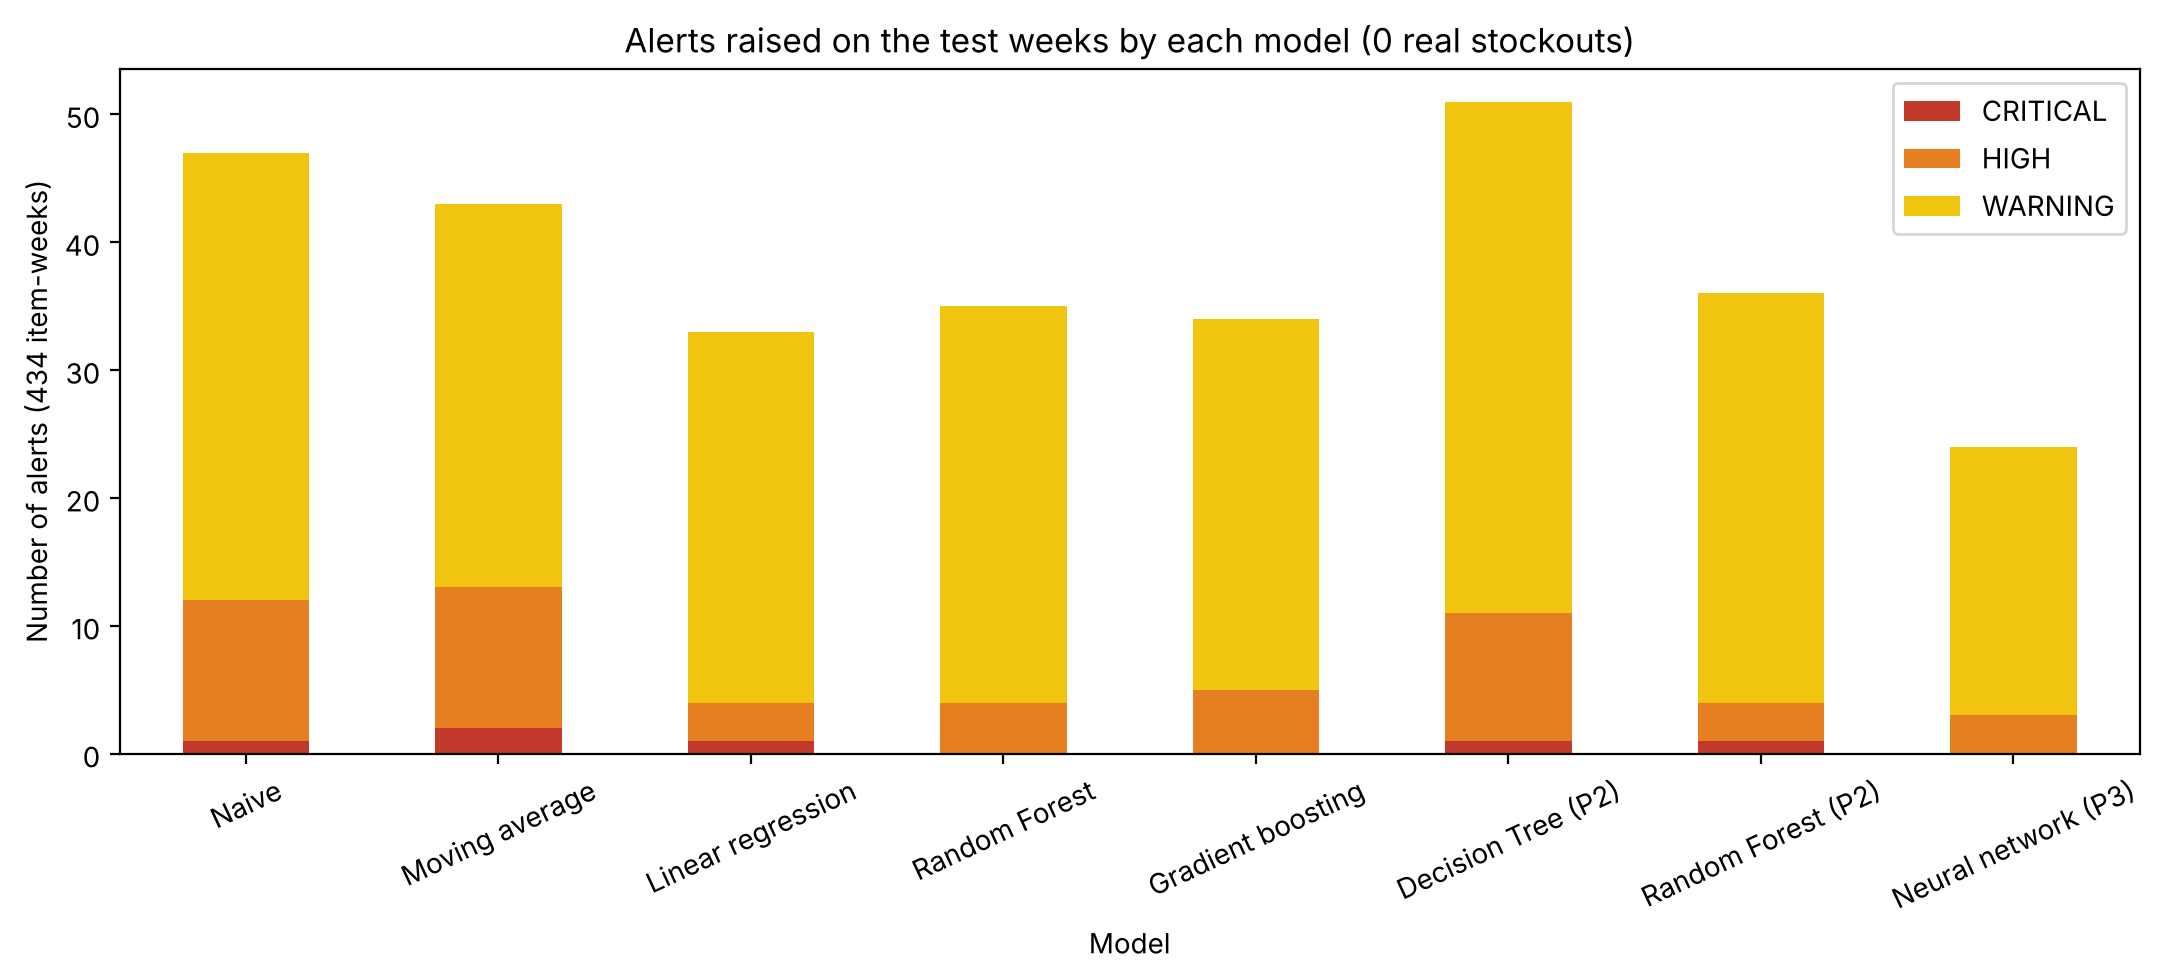

In [27]:
summary.set_index('Model')[['CRITICAL', 'HIGH', 'WARNING']].plot(
    kind='bar', stacked=True, figsize=(11, 5), rot=25,
    color=[COLORS['CRITICAL'], COLORS['HIGH'], COLORS['WARNING']])
plt.ylabel(f'Number of alerts ({len(test_df)} item-weeks)')
plt.title(f"Alerts raised on the test weeks by each model ({int(test_df['stockout_this_week'].sum())} real stockouts)")
plt.tight_layout()
plt.savefig('fig_test_alerts.png', dpi=150)
plt.show()

In [28]:
n_so = int(test_df['stockout_this_week'].sum())
fa = summary.set_index('Model')['false_alarms_crit_high']
print(f'Real stockouts in the {test_df.week_end.nunique()} test weeks: {n_so}')
if n_so == 0:
    print('So every CRITICAL/HIGH alert on the test split is a false alarm and recall cannot be measured.')
print('False alarms (CRITICAL + HIGH) per model:', fa.to_dict())

Real stockouts in the 31 test weeks: 0
So every CRITICAL/HIGH alert on the test split is a false alarm and recall cannot be measured.
False alarms (CRITICAL + HIGH) per model: {'Naive': 12, 'Moving average': 13, 'Linear regression': 4, 'Random Forest': 4, 'Gradient boosting': 5, 'Decision Tree (P2)': 11, 'Random Forest (P2)': 4, 'Neural network (P3)': 3}


### 16b. Walk-forward backtest over a longer period with real stockouts
The test split has no stockouts, so to check whether the alerts **catch** them we replay the last **83 weeks** of the CSV (March 2025 to the end, 15 real stockouts). Every 4 weeks the models are retrained on **all weeks before** that point and then forecast the next 4 weeks, so each forecast only uses the past, like it would in real use.

In [29]:
BT_WEEKS, REFIT_EVERY = 83, 4
bt_weeks = weeks[-BT_WEEKS:]
parts = []
for i in range(0, len(bt_weeks), REFIT_EVERY):
    block = bt_weeks[i:i + REFIT_EVERY]
    tr = df[df['week_end'] < block[0]]
    te = df[df['week_end'].isin(block)]
    parts.append(fit_predict(tr, te))
wf_preds = pd.concat(parts)
wf_rows = df.loc[wf_preds.index]

wf_long = pd.concat([run_alerts(wf_rows, wf_preds[m]).assign(model=m) for m in MODELS], ignore_index=True)
wf_long.to_csv('outputs/walkforward_alerts_all_models.csv', index=False)

wf_scores = pd.concat([scores_table(wf_long[wf_long['model'] == m]).assign(model=m) for m in MODELS],
                      ignore_index=True)[['model', 'flag', 'TP', 'FP', 'FN', 'TN', 'precision', 'recall']]
wf_scores.to_csv('outputs/walkforward_alert_scores.csv', index=False)

wf_mae = pd.DataFrame([dict(Model=m, **metrics(wf_rows['demand_units'], wf_preds[m])) for m in MODELS])
print(f"{pd.Timestamp(bt_weeks[0]).date()} to {pd.Timestamp(bt_weeks[-1]).date()}: "
      f"{len(bt_weeks)} weeks x {wf_rows['sku'].nunique()} items = {len(wf_rows)} checks, "
      f"{int(wf_rows['stockout_this_week'].sum())} real stockouts")
print(wf_mae.to_string(index=False))
wf_scores[wf_scores['flag'] == 'CRITICAL, HIGH'].reset_index(drop=True)

2025-03-30 to 2026-10-25: 83 weeks x 14 items = 1162 checks, 15 real stockouts
            Model   MAE  RMSE
            Naive 25.92 42.56
   Moving average 26.87 50.52
Linear regression 24.56 38.86
    Random Forest 21.33 36.31
Gradient boosting 22.91 37.19


,model,flag,TP,FP,FN,TN,precision,recall
0,Naive,"CRITICAL, HIGH",11,50,4,1097,0.180,0.733
1,Moving average,"CRITICAL, HIGH",8,40,7,1107,0.167,0.533
2,Linear regression,"CRITICAL, HIGH",9,35,6,1112,0.205,0.600
3,Random Forest,"CRITICAL, HIGH",10,27,5,1120,0.270,0.667
4,Gradient boosting,"CRITICAL, HIGH",10,30,5,1117,0.250,0.667


In [30]:
wf_scores

,model,flag,TP,FP,FN,TN,precision,recall
0,Naive,CRITICAL,7,7,8,1140,0.500,0.467
1,Naive,"CRITICAL, HIGH",11,50,4,1097,0.180,0.733
2,Naive,"CRITICAL, HIGH, WARNING",13,150,2,997,0.080,0.867
3,Moving average,CRITICAL,5,7,10,1140,0.417,0.333
4,Moving average,"CRITICAL, HIGH",8,40,7,1107,0.167,0.533
5,Moving average,"CRITICAL, HIGH, WARNING",11,148,4,999,0.069,0.733
6,Linear regression,CRITICAL,7,2,8,1145,0.778,0.467
7,Linear regression,"CRITICAL, HIGH",9,35,6,1112,0.205,0.600
8,Linear regression,"CRITICAL, HIGH, WARNING",11,125,4,1022,0.081,0.733
9,Random Forest,CRITICAL,8,5,7,1142,0.615,0.533


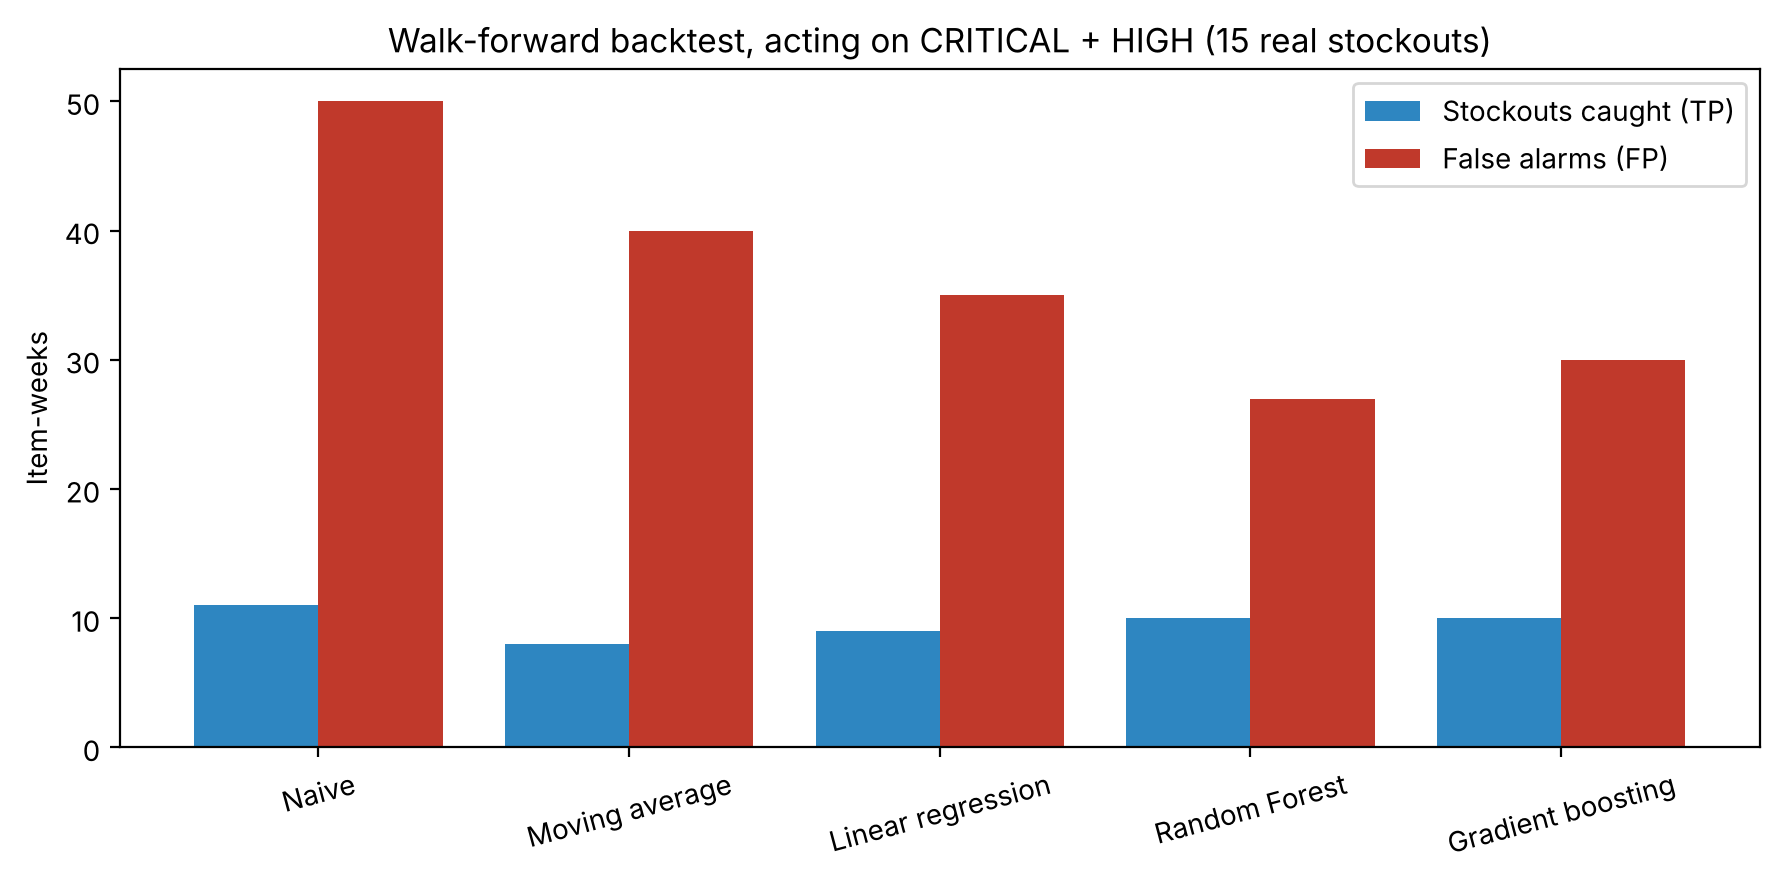

In [31]:
ch = wf_scores[wf_scores['flag'] == 'CRITICAL, HIGH'].set_index('model')
fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(ch))
ax.bar(x - 0.2, ch['TP'], 0.4, label='Stockouts caught (TP)', color='#2e86c1')
ax.bar(x + 0.2, ch['FP'], 0.4, label='False alarms (FP)', color='#c0392b')
ax.set_xticks(x)
ax.set_xticklabels(ch.index, rotation=15)
ax.set_ylabel('Item-weeks')
ax.set_title(f'Walk-forward backtest, acting on CRITICAL + HIGH '
             f"({int(wf_rows['stockout_this_week'].sum())} real stockouts)")
ax.legend()
plt.tight_layout()
plt.savefig('fig_walkforward_alerts.png', dpi=150)
plt.show()

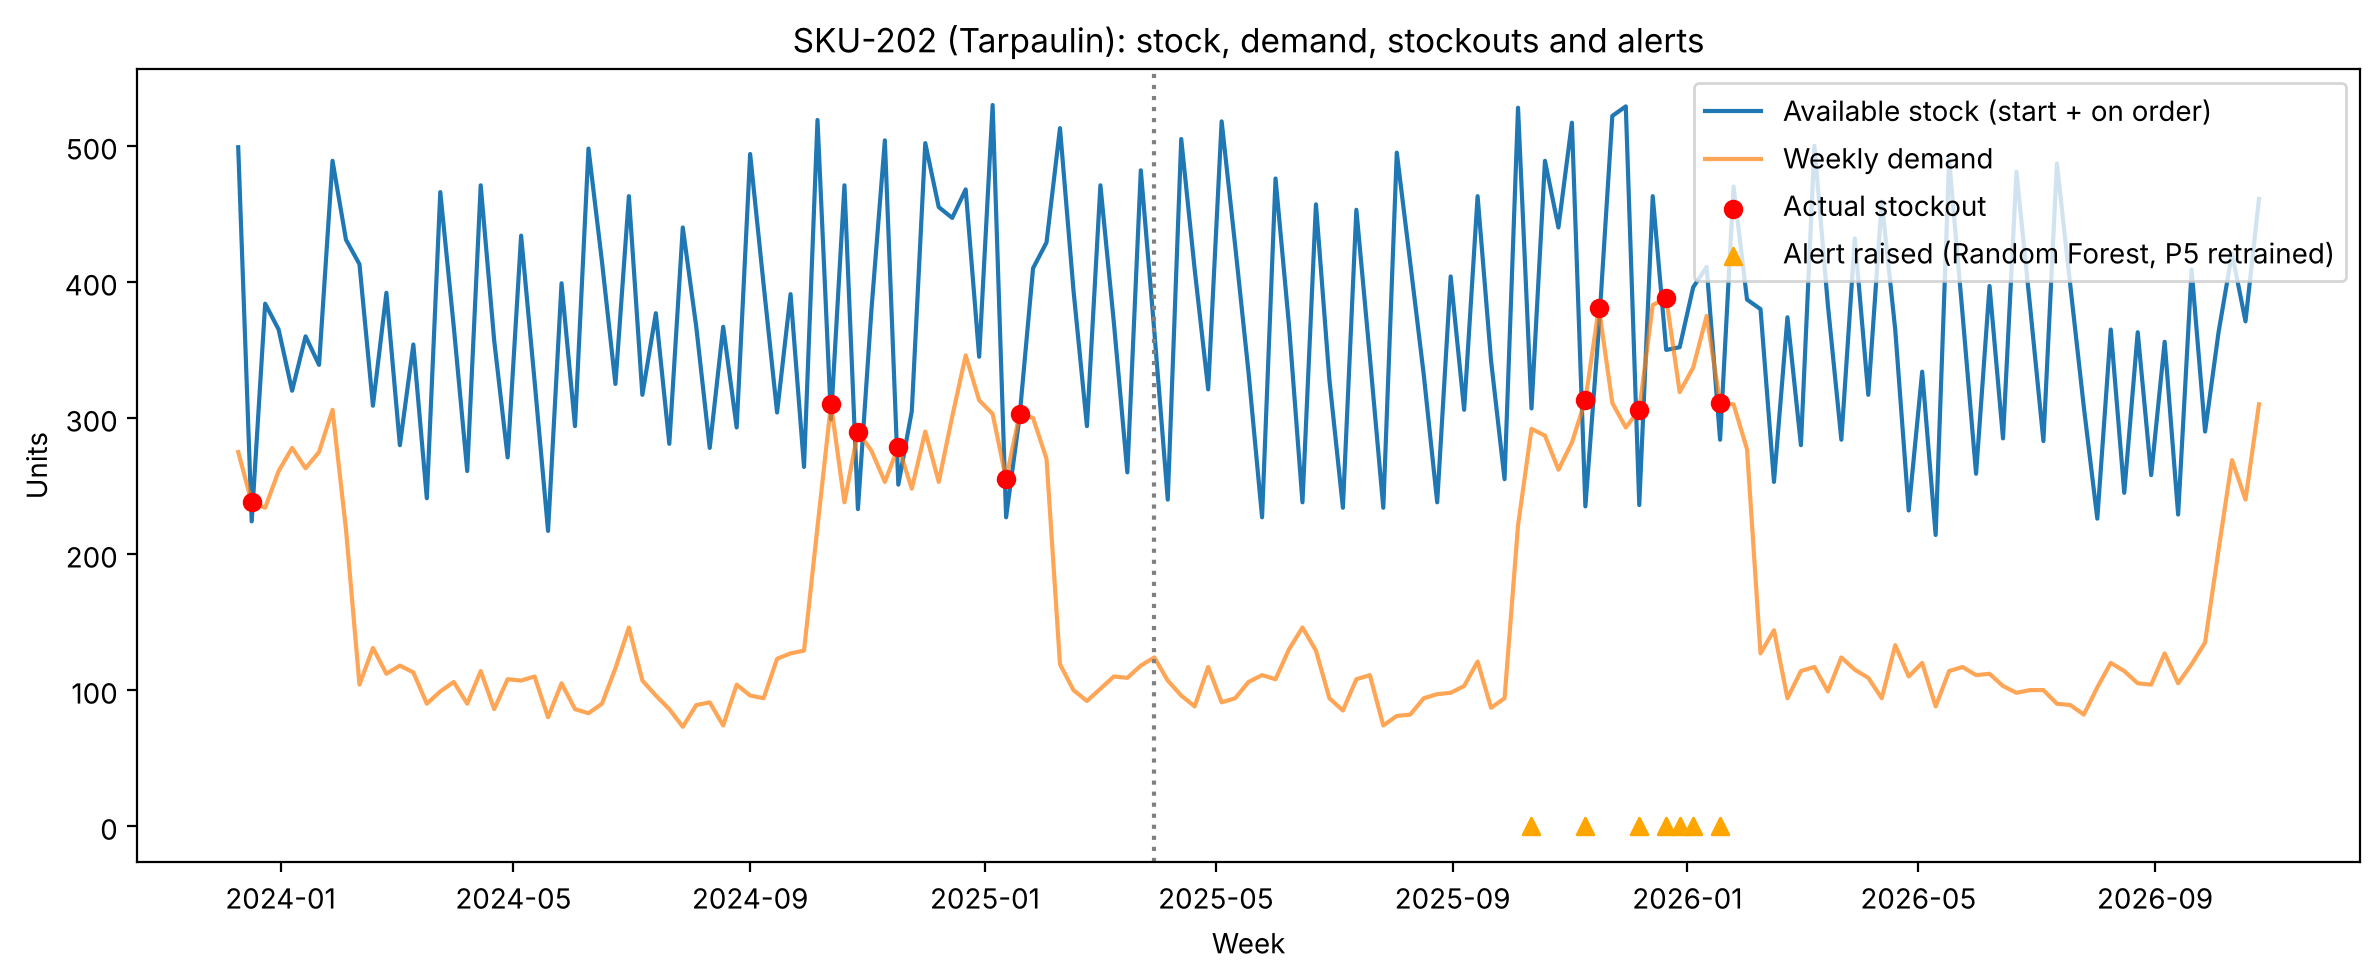

In [32]:
sku = wf_rows.groupby('sku')['stockout_this_week'].sum().idxmax()   # item with the most stockouts
g = df[df['sku'] == sku]
WF_MODEL = BEST if BEST in MODELS else 'Random Forest'   # team models only cover the test weeks
b = wf_long[(wf_long['model'] == WF_MODEL) & (wf_long['sku'] == sku)]
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(g['week_end'], g['stock_start_units'] + g['on_order_start_units'], label='Available stock (start + on order)')
ax.plot(g['week_end'], g['demand_units'], label='Weekly demand', alpha=.7)
so = g[g['stockout_this_week'] == 1]
ax.scatter(so['week_end'], so['demand_units'], c='red', zorder=5, label='Actual stockout')
fl = b[b['alert'].isin(['CRITICAL', 'HIGH'])]
ax.scatter(fl['week_end'], [0] * len(fl), marker='^', c='orange', zorder=4, label=f'Alert raised ({WF_MODEL}, P5 retrained)')
ax.axvline(bt_weeks[0], ls=':', c='grey')
ax.set_title(f"{sku} ({g['item_name'].iloc[0]}): stock, demand, stockouts and alerts")
ax.set_xlabel('Week')
ax.set_ylabel('Units')
ax.legend()
plt.tight_layout()
plt.savefig('fig_example_sku_alerts.png', dpi=150)
plt.show()

## 17. Saved outputs

In [33]:
print('Saved to outputs/:')
for fname in sorted(os.listdir('outputs')):
    print('  ', fname)

Saved to outputs/:
   forecast_metrics_test.csv
   shortage_alerts_latest.csv
   test_alert_summary.csv
   test_alerts_all_models.csv
   walkforward_alert_scores.csv
   walkforward_alerts_all_models.csv


## Summary of integration and shortage detection

In [34]:
ch = wf_scores[wf_scores['flag'] == 'CRITICAL, HIGH'].set_index('model')
print('Data: clean_weekly_demand.csv + all_test_predictions.csv')
print(f"Best forecast on the test split: {BEST} (MAE {forecast_metrics.loc[0, 'MAE']}, RMSE {forecast_metrics.loc[0, 'RMSE']})")
print(f"Test split: {int(test_df['stockout_this_week'].sum())} real stockouts; CRITICAL/HIGH false alarms per model:",
      summary.set_index('Model')['false_alarms_crit_high'].to_dict())
print(f"Walk-forward ({len(bt_weeks)} weeks, {int(wf_rows['stockout_this_week'].sum())} stockouts), acting on CRITICAL + HIGH:")
for m, r in ch.iterrows():
    print(f"  {m:18s} caught {r['TP']:2d} of {r['TP'] + r['FN']} (recall {r['recall']:.2f}), false alarms {r['FP']}")

Data: clean_weekly_demand.csv + all_test_predictions.csv
Best forecast on the test split: Random Forest (P2) (MAE 19.88, RMSE 31.16)
Test split: 0 real stockouts; CRITICAL/HIGH false alarms per model: {'Naive': 12, 'Moving average': 13, 'Linear regression': 4, 'Random Forest': 4, 'Gradient boosting': 5, 'Decision Tree (P2)': 11, 'Random Forest (P2)': 4, 'Neural network (P3)': 3}
Walk-forward (83 weeks, 15 stockouts), acting on CRITICAL + HIGH:
  Naive              caught 11 of 15 (recall 0.73), false alarms 50
  Moving average     caught  8 of 15 (recall 0.53), false alarms 40
  Linear regression  caught  9 of 15 (recall 0.60), false alarms 35
  Random Forest      caught 10 of 15 (recall 0.67), false alarms 27
  Gradient boosting  caught 10 of 15 (recall 0.67), false alarms 30


**Main point:** the alert rule turns any demand forecast into a reorder signal. Acting on CRITICAL + HIGH, Random Forest (the most accurate forecast) catches 10 of 15 stockouts with 27 false alarms, the best precision of all models. Naive catches one more (11) but raises almost twice as many false alarms (50), and the moving average catches fewer (8) with 40. So a better forecast mainly cuts **unnecessary emergency orders**.

**Limitations:** the test split has no stockouts, so recall is measured on the walk-forward period instead; the alert only looks at the current week because the CSV gives incoming orders for one week only; the team's Decision Tree and Neural network only have test-week predictions, so they are not in the walk-forward backtest.